<a href="https://colab.research.google.com/github/Idrisadelowo/Agentic-AI-and-Foundational-Model-in-Civil-and-Building-Engineering/blob/feature%2FInside_Transformer/02_transformer_inspection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hands-On 2: Inside a Transformer

Agentic AI and Foundation Models in Civil and Building Engineering, TUM, WS 2026/27

> **Disclaimer**: For teaching purposes only. Partially generated with an LLM. Not production code.

On Colab: **File ▸ Upload notebook**, then **Runtime ▸ Change runtime type ▸ T4 GPU**. CPU also works, only slower.

1. **Mini transformer** - one decoder, built by hand: embeddings, attention, feed-forward
2. **A real model** - open Qwen3-0.6B, map it to the lecture figure, generate text

In [ ]:
%pip install -q "transformers>=4.51" accelerate
# !uv add "transformers>=4.51" accelerate

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from transformers import AutoTokenizer

torch.manual_seed(0)
tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen3-0.6B")

sentence = "The handrail shall be at least 1.0 m high"
ids = torch.tensor(tokenizer(sentence)["input_ids"])
labels = [tokenizer.decode([i]) for i in ids]
T = len(ids)
print(T, "tokens:", labels)

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

13 tokens: ['The', ' hand', 'rail', ' shall', ' be', ' at', ' least', ' ', '1', '.', '0', ' m', ' high']


---
# Part 1 - Mini Transformer

We build the decoder from the lecture figure, box by box. Small sizes, random weights, no training:
the point is to see what each box does to the shapes.

| Size | Mini | Qwen3-0.6B |
|---|---|---|
| `d_model` (vector per token) | 64 | 1024 |
| attention heads | 4 | 16 |
| feed-forward hidden size | 256 | 3072 |
| blocks | 2 | 28 |

In [ ]:
vocab_size = len(tokenizer)
d_model, n_heads, d_ff, n_blocks, max_len = 64, 4, 256, 2, 128

## 1.1 Input embedding + positional encoding

Two lookup tables: one row per token ID, one row per position. Their sum is the input to the first block.

In [ ]:
tok_emb = nn.Embedding(vocab_size, d_model)
pos_emb = nn.Embedding(max_len, d_model)

x = tok_emb(ids) + pos_emb(torch.arange(T))
print("token ids :", tuple(ids.shape))
print("embeddings:", tuple(x.shape), "-> one vector of", d_model, "numbers per token")

token ids : (13,)
embeddings: (13, 64) -> one vector of 64 numbers per token


## 1.2 Self-attention, one head by hand

Each token asks a **query** (q), offers a **key** (k) and carries a **value** (v).
Score = q · k: how much token *i* should look at token *j*.

1. Project x to q, k, v
2. Scores = q kᵀ / √d
3. **Causal mask**: a token may not look at later tokens
4. Softmax per row → attention weights that sum to 1
5. Output = weights · v, a weighted mix of the values

In [ ]:
d_head = d_model // n_heads
W_q, W_k, W_v = (nn.Linear(d_model, d_head, bias=False) for _ in range(3))

h = nn.LayerNorm(d_model)(x)
q, k, v = W_q(h), W_k(h), W_v(h)                     # (T, d_head) each

scores = q @ k.T / d_head ** 0.5                     # (T, T)
mask = torch.triu(torch.ones(T, T, dtype=torch.bool), diagonal=1)
scores = scores.masked_fill(mask, float("-inf"))     # no looking ahead
weights = scores.softmax(dim=-1)                      # each row sums to 1
out = weights @ v                                     # (T, d_head)

print("q, k, v :", tuple(q.shape))
print("weights :", tuple(weights.shape))
print("output  :", tuple(out.shape))

q, k, v : (13, 16)
weights : (13, 13)
output  : (13, 16)


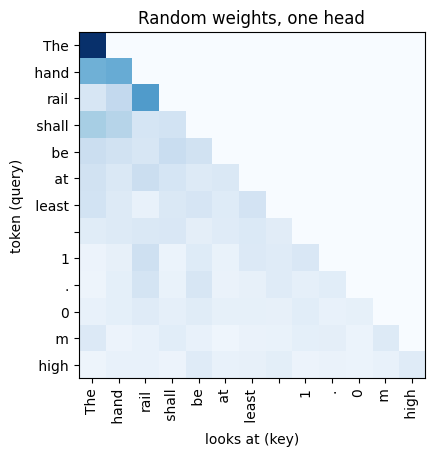

In [ ]:
def plot_attention(w, title, ax=None):
    ax = ax or plt.figure(figsize=(5, 4.5)).gca()
    ax.imshow(w.detach().float().cpu(), cmap="Blues")
    ax.set_xticks(range(len(labels)), labels, rotation=90)
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel("looks at (key)")
    ax.set_ylabel("token (query)")
    ax.set_title(title)

plot_attention(weights, "Random weights, one head")
plt.show()

The upper triangle is empty: that is the causal mask. With random weights, each token spreads its
attention over the earlier tokens without a pattern. Training turns these weights into useful patterns
(Part 2).

## 1.3 The full decoder - Optional

The same steps as modules. **Multi-head**: `n_heads` heads of size `d_model / n_heads` run in parallel,
each can learn a different pattern. The two `Linear` boxes around attention in the figure are the
q/k/v projection and `out_proj`.

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.n_heads, self.d_head = n_heads, d_model // n_heads
        self.qkv_proj = nn.Linear(d_model, 3 * d_model)   # q, k, v for all heads in one matrix
        self.out_proj = nn.Linear(d_model, d_model)

    def forward(self, x):
        T = x.shape[0]
        # (T, 3 * d_model) -> 3 x (n_heads, T, d_head)
        q, k, v = self.qkv_proj(x).view(T, 3, self.n_heads, self.d_head).permute(1, 2, 0, 3)
        scores = q @ k.transpose(-2, -1) / self.d_head ** 0.5
        mask = torch.triu(torch.ones(T, T, dtype=torch.bool), diagonal=1)
        self.weights = scores.masked_fill(mask, float("-inf")).softmax(dim=-1)   # kept for plotting
        out = (self.weights @ v).transpose(0, 1).reshape(T, -1)                  # heads side by side
        return self.out_proj(out)


class FeedForward(nn.Module):
    """Linear -> GeLU -> Linear, applied to each token on its own."""
    def __init__(self, d_model, d_ff):
        super().__init__()
        self.up = nn.Linear(d_model, d_ff)
        self.act = nn.GELU()
        self.down = nn.Linear(d_ff, d_model)

    def forward(self, x):
        return self.down(self.act(self.up(x)))


class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, n_heads)
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = FeedForward(d_model, d_ff)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))   # residual connection: the "+" in the figure
        x = x + self.ffn(self.ln2(x))
        return x


class MiniGPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.blocks = nn.ModuleList(TransformerBlock(d_model, n_heads, d_ff) for _ in range(n_blocks))
        self.ln_f = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size)

    def forward(self, ids):
        x = self.tok_emb(ids) + self.pos_emb(torch.arange(len(ids)))
        for block in self.blocks:
            x = block(x)
        return self.lm_head(self.ln_f(x))   # logits: one score per vocabulary entry


mini = MiniGPT()
print(mini)

MiniGPT(
  (tok_emb): Embedding(151669, 64)
  (pos_emb): Embedding(128, 64)
  (blocks): ModuleList(
    (0-1): 2 x TransformerBlock(
      (ln1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (attn): MultiHeadAttention(
        (qkv_proj): Linear(in_features=64, out_features=192, bias=True)
        (out_proj): Linear(in_features=64, out_features=64, bias=True)
      )
      (ln2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (ffn): FeedForward(
        (up): Linear(in_features=64, out_features=256, bias=True)
        (act): GELU(approximate='none')
        (down): Linear(in_features=256, out_features=64, bias=True)
      )
    )
  )
  (ln_f): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (lm_head): Linear(in_features=64, out_features=151669, bias=True)
)


In [ ]:
logits = mini(ids)
print("logits:", tuple(logits.shape), "-> for every position, a score for each of", vocab_size, "tokens")

probs = logits[-1].softmax(dim=-1)        # next token after the last input token
top = probs.topk(5)
print("\nNext token after", repr(sentence))
for p, i in zip(top.values, top.indices):
    print(f"  {p:.5f}  {tokenizer.decode([i])!r}")

logits: (13, 151669) -> for every position, a score for each of 151669 tokens

Next token after 'The handrail shall be at least 1.0 m high'
  0.00007  ' Students'
  0.00006  '.transition'
  0.00006  'sparse'
  0.00006  'יחוד'
  0.00005  '笫'


Untrained: all probabilities are close to 1 / vocab size and the top tokens are random. Training adjusts
all weights so that the true next token gets a high probability.

In [ ]:
n_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"Embeddings    : {n_params(mini.tok_emb) + n_params(mini.pos_emb):>10,}")
print(f"Attention     : {sum(n_params(b.attn) for b in mini.blocks):>10,}")
print(f"Feed-forward  : {sum(n_params(b.ffn) for b in mini.blocks):>10,}")
print(f"Output head   : {n_params(mini.lm_head):>10,}")
print(f"Total         : {n_params(mini):>10,}")

Embeddings    :  9,715,008
Attention     :     33,280
Feed-forward  :     66,176
Output head   :  9,858,485
Total         : 19,673,589


**Optional Experiments**
- Most parameters sit in two layers. Which ones, and why?
- Change `n_blocks` or `d_model` in the size cell and rerun. How does the parameter count grow?

---
# Part 2 - A Real Model: Qwen3-0.6B

Qwen3-0.6B (Qwen Team, 2025) is a small open model, ~1.2 GB download. Same recipe as our mini model,
trained on trillions of tokens.

In [ ]:
from transformers import AutoModelForCausalLM

device = "cuda" if torch.cuda.is_available() else "cpu"
model = AutoModelForCausalLM.from_pretrained(
    "Qwen/Qwen3-0.6B",
    dtype=torch.float16 if device == "cuda" else torch.float32,
    attn_implementation="eager",   # needed to read out attention weights
).to(device)
model.eval()
print(model)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Qwen3ForCausalLM(
  (model): Qwen3Model(
    (embed_tokens): Embedding(151936, 1024)
    (layers): ModuleList(
      (0-27): 28 x Qwen3DecoderLayer(
        (self_attn): Qwen3Attention(
          (q_proj): Linear(in_features=1024, out_features=2048, bias=False)
          (k_proj): Linear(in_features=1024, out_features=1024, bias=False)
          (v_proj): Linear(in_features=1024, out_features=1024, bias=False)
          (o_proj): Linear(in_features=2048, out_features=1024, bias=False)
          (q_norm): Qwen3RMSNorm((128,), eps=1e-06)
          (k_norm): Qwen3RMSNorm((128,), eps=1e-06)
        )
        (mlp): Qwen3MLP(
          (gate_proj): Linear(in_features=1024, out_features=3072, bias=False)
          (up_proj): Linear(in_features=1024, out_features=3072, bias=False)
          (down_proj): Linear(in_features=3072, out_features=1024, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen3RMSNorm((1024,), eps=1e-06)
        (post_attention_layer

In [ ]:
cfg = model.config
print(f"Parameters      : {n_params(model) / 1e9:.2f} B")
print(f"d_model         : {cfg.hidden_size}")
print(f"Blocks          : {cfg.num_hidden_layers}")
print(f"Query heads     : {cfg.num_attention_heads}")
print(f"Key/value heads : {cfg.num_key_value_heads}")
print(f"Feed-forward    : {cfg.intermediate_size}, activation {cfg.hidden_act}")
print(f"Vocabulary      : {cfg.vocab_size:,}")
print(f"Context length  : {cfg.max_position_embeddings:,}")

Parameters      : 0.60 B
d_model         : 1024
Blocks          : 28
Query heads     : 16
Key/value heads : 8
Feed-forward    : 3072, activation silu
Vocabulary      : 151,936
Context length  : 40,960


## 2.1 Qwen3 and the lecture figure

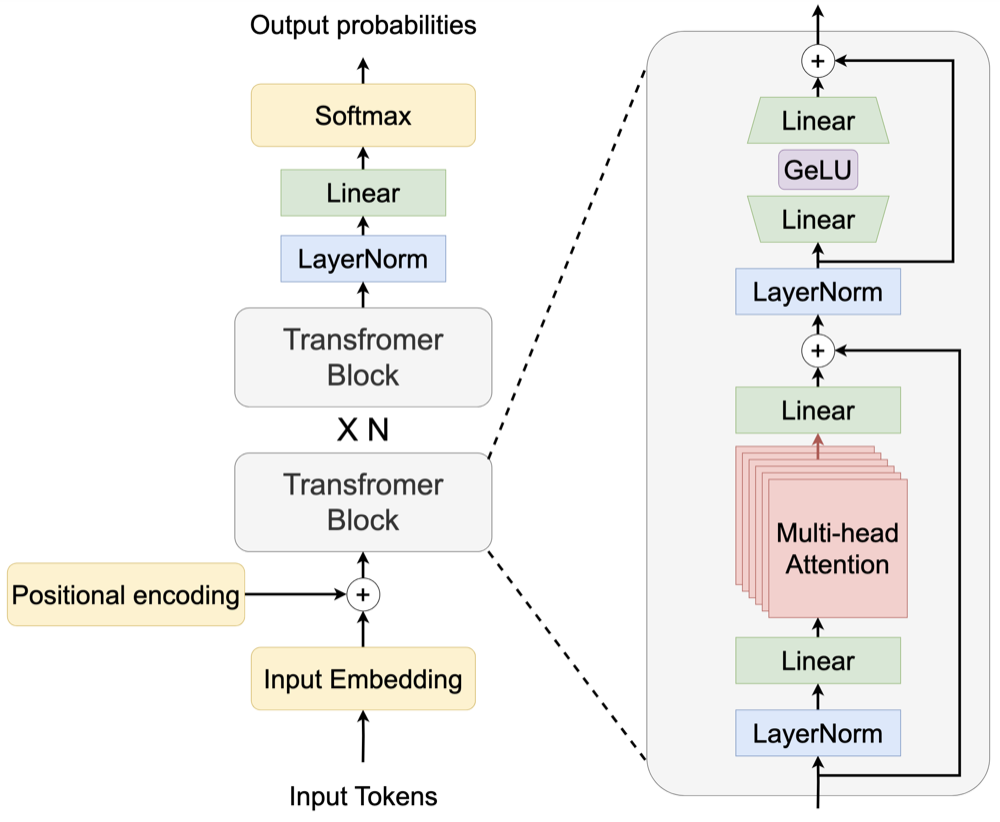

Source: Chalvatzaki et al., 2023, Learning to Reason over Scene Graphs, arXiv:2305.07716, Figure 2

**Your turn**
- Compare `print(model)` and the config with the decoder figure from the lecture.
- For each box of the figure, find the Qwen3 module and note down if anything changed.

Hints: `cfg.num_attention_heads`, `cfg.num_key_value_heads`, `cfg.tie_word_embeddings`.

Going further: Raschka (2025), [The Big LLM Architecture Comparison](https://magazine.sebastianraschka.com/p/the-big-llm-architecture-comparison), compares recent open models, Qwen3 included.

## 2.2 Embeddings

`embed_tokens` is the lookup table from 1.1, now trained: 151,936 rows of 1024 numbers.
Nearest tokens by cosine similarity:

In [ ]:
E = model.model.embed_tokens.weight.float()
E_norm = E / E.norm(dim=1, keepdim=True)

def nearest_tokens(word, k=8):
    i = tokenizer(word)["input_ids"][0]          # first token of the word
    sims = E_norm @ E_norm[i]
    return [tokenizer.decode([j]) for j in sims.topk(k + 1).indices[1:]]

for word in [" concrete", " steel", " stair", " beam", " shall"]:
    print(f"{word!r:<11}", nearest_tokens(word))

' concrete' [' Concrete', 'Concrete', '混凝土', ' конкрет', '砼', ' tangible', '具体', '具体的']
' steel'    [' Steel', 'steel', 'Steel', '钢', '鋼', '钢铁', '钢材', ' stainless']
' stair'    [' stairs', ' staircase', '楼梯', 'stairs', '台阶', '阶梯', ' stepping', '㟃']
' beam'     [' Beam', ' beams', 'Beam', 'beam', '_beam', '-be', '_BE', '.be']
' shall'    ['shall', ' Shall', ' SHALL', ' shalt', ' will', ' should', 'will', '应当']


These are input vectors only, before any attention. The blocks then mix in context, so ` beam` ends up
with a different vector in "steel beam" than in "laser beam".

## 2.3 Attention

The weights of every head in every block, for our sentence. Early blocks often show simple patterns
(look at the previous token, look at the first token); later blocks are harder to read.


Attention weights for the sentence: 'The handrail shall be at least 1.0 m high'
28 blocks, each (1, 16, 13, 13) = (batch, heads, query, key)


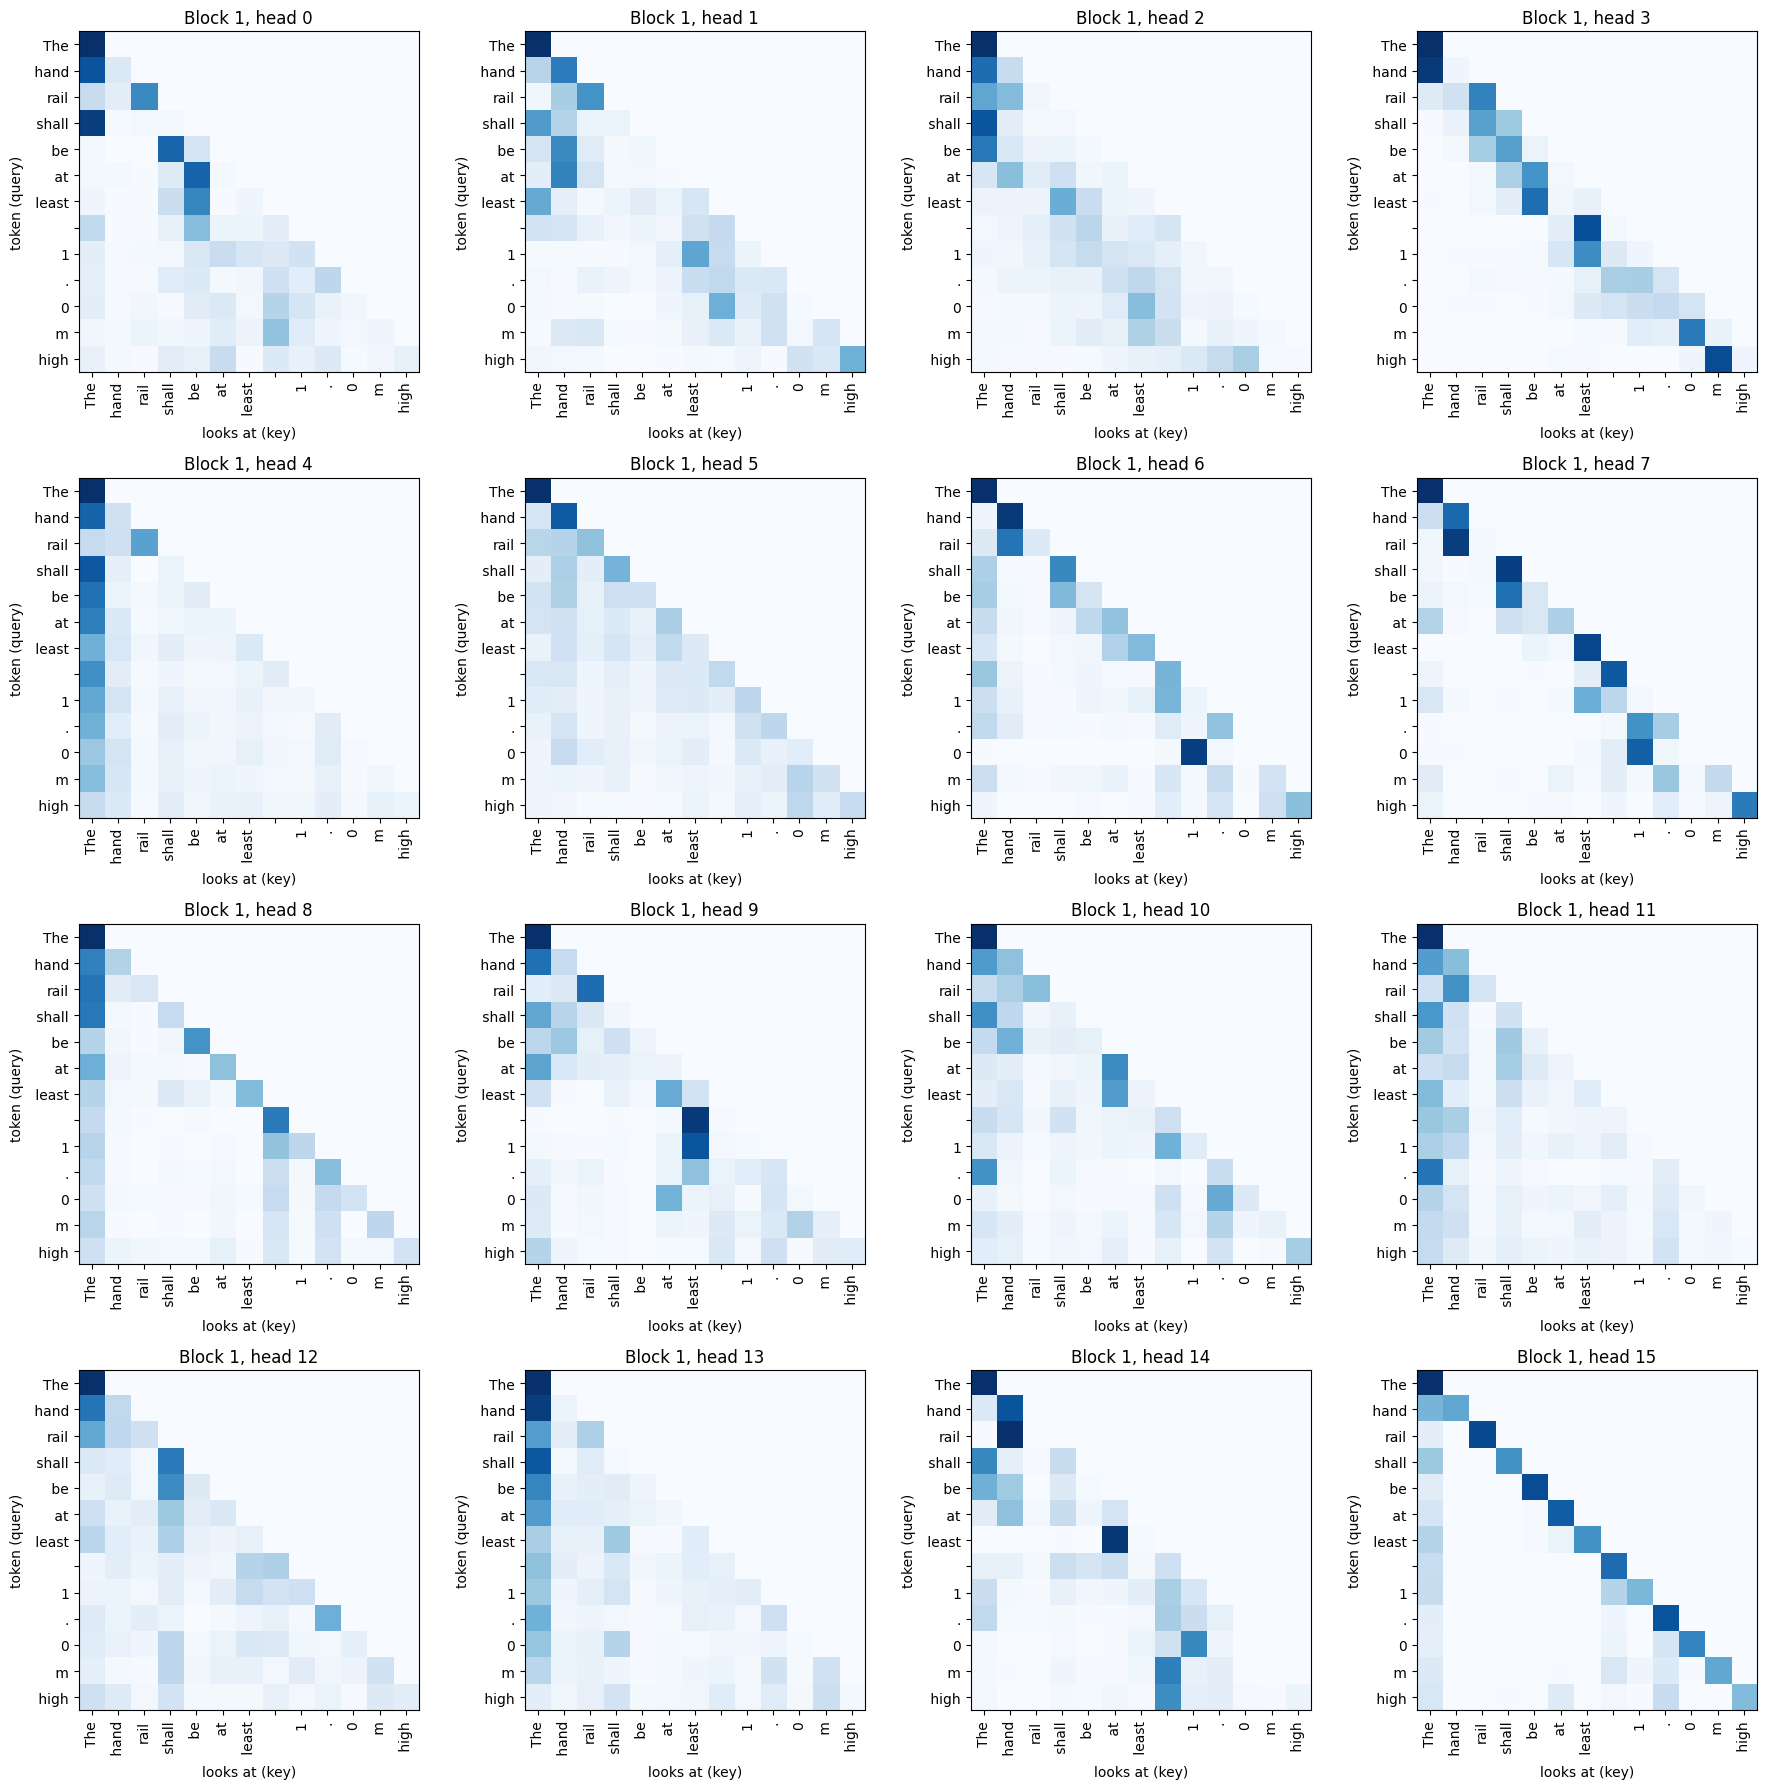

In [ ]:
print("\nAttention weights for the sentence:", repr(sentence))
inputs = tokenizer(sentence, return_tensors="pt").to(device)
with torch.no_grad():
    out = model(**inputs, output_attentions=True)

print(len(out.attentions), "blocks, each", tuple(out.attentions[0].shape), "= (batch, heads, query, key)")

LAYER = 1
fig, axes = plt.subplots(4, 4, figsize=(18, 18))
for head, ax in enumerate(axes.flat):
    plot_attention(out.attentions[LAYER][0, head], f"Block {LAYER}, head {head}", ax)
plt.tight_layout()
plt.show()

**Optional Experiments**
- Change `LAYER` (0 to 27). Find a head that looks at the previous token, and one that puts almost all
  weight on the first token.
- Which word does ` high` attend to most in a later block?

## 2.4 Feed-forward

`mlp` in every block. Three matrices instead of two: `gate_proj` and `up_proj` both widen 1024 → 3072,
their outputs are multiplied (one through [SiLU](https://arxiv.org/abs/1702.03118)), then `down_proj` maps back to 1024.

In [ ]:
mlp = model.model.layers[0].mlp
for name, p in mlp.named_parameters():
    print(f"{name:<18} {tuple(p.shape)}")

blocks = model.model.layers
print()
print(f"Embeddings   : {n_params(model.model.embed_tokens) / 1e6:6.0f} M")
print(f"Attention    : {sum(n_params(b.self_attn) for b in blocks) / 1e6:6.0f} M")
print(f"Feed-forward : {sum(n_params(b.mlp) for b in blocks) / 1e6:6.0f} M")

gate_proj.weight   (3072, 1024)
up_proj.weight     (3072, 1024)
down_proj.weight   (1024, 3072)

Embeddings   :    156 M
Attention    :    176 M
Feed-forward :    264 M


**Optional Experiments**
- Compare the split with the mini model in 1.3. Where do most parameters sit now?

## 2.5 Generating text

Generation is a loop: predict the next token, append it, run the model again. Here the model always takes the
most likely token.

In [ ]:
messages = [{"role": "user", "content": "Why do stairs need handrails?"}]
text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
ids = tokenizer(text, return_tensors="pt")["input_ids"].to(device)

for _ in range(150):
    with torch.no_grad():
        logits = model(ids).logits[0, -1]
    next_id = logits.argmax()                           # most likely next token
    if next_id == tokenizer.eos_token_id:
        break
    ids = torch.cat([ids, next_id.view(1, 1)], dim=1)   # append it and run again
    print(tokenizer.decode([next_id]), end="")

Stairs need handrails for several important reasons:

1. **Safety**: Handrails provide a safe way to walk on stairs, especially when someone is standing on the edge. They prevent falls and help with balance.

2. **Protection**: Handrails protect against injuries from falls, especially in areas where stairs are frequently used.

3. **Accessibility**: Handrails make stairs easier to navigate for people with disabilities, ensuring they can use the stairs safely.

4. **Prevention of Falls**: They reduce the risk of falls by keeping the person in a stable position when walking on the edge.

5. **Legal Compliance**: Many places require handrails on stairs to comply with safety regulations and improve public safety.

In summary, handrails are essential for safety

---
## Solutions

<details>
<summary>Click to show</summary>

**1.3** The embedding table and the output head: both have one row per vocabulary entry
(151,669 × 64). Doubling `n_blocks` adds attention and feed-forward weights only; doubling `d_model`
doubles the two tables and roughly quadruples each block.
This holds for the mini model only (d = 64): in Qwen3-0.6B the 28 blocks hold 440 M parameters, the shared
embedding 156 M (see 2.4).

**2.1** Visible in `print(model)`:

| Figure box | Qwen3 module | What changed? |
|---|---|---|
| Positional encoding | `rotary_emb` | **RoPE**: positions rotate q and k inside attention instead of being added to the input (A.3) |
| LayerNorm | `input_layernorm`, `post_attention_layernorm`, `norm` | **RMSNorm**: no mean subtraction, no bias (A.2) |
| Linear → Multi-head attention → Linear | `q_proj`, `k_proj`, `v_proj` → `o_proj` | **Grouped-query attention** (A.4): `k_proj`, `v_proj` half the size of `q_proj` (1024 vs 2048), as 16 query heads share 8 key/value heads; **QK-norm** (`q_norm`, `k_norm`); no biases |
| Linear → [GeLU](https://arxiv.org/abs/1606.08415) → Linear | `gate_proj`, `up_proj` → SiLU → `down_proj` | GeLU → **SiLU**: similar curve (A.1); **SwiGLU**: a third matrix gates the hidden layer |

Only in the config:
- **Tied output head**: `tie_word_embeddings` is `True`, so `lm_head` and `embed_tokens` are one matrix
  (`model.lm_head.weight is model.model.embed_tokens.weight` is `True`).

**2.3** Previous token: block 2, head 12 or block 15, head 3 (a line just below the diagonal).
First token: from block 3 on, most heads put 60 to 90 % of their weight on `The`, e.g. block 19, head 4 (almost 100 %).
` high` also attends mostly to `The`. Apart from that, block 6, head 1 links ` high` to `rail` (88 %): the
requirement to its subject. Block 15, head 3 links it to ` m`.

Why the first token? Softmax makes every row sum to 1, so a head that finds nothing relevant still has to put
its weight somewhere. Models learn to park it on the first token, which every position can see. This is
called an **attention sink** (Xiao et al., 2023).
Why not attend to itself? That would add its own value vector, while the first token's value vector is
small, so weight parked there changes almost nothing.

**2.4** Feed-forward 264 M, attention 176 M: the feed-forward layers hold 60 % of the block weights.
The embedding table (156 M) is a quarter of this small model; in larger models its share shrinks.

</details>

---
# Appendix

## A.1 Activation functions

The non-linearity inside the feed-forward block. **ReLU** cuts all negative values to 0. **GELU** (GPT-2, lecture
figure) and **SiLU** (Qwen3) are smooth versions: small negative values pass a little, with a dip below 0.

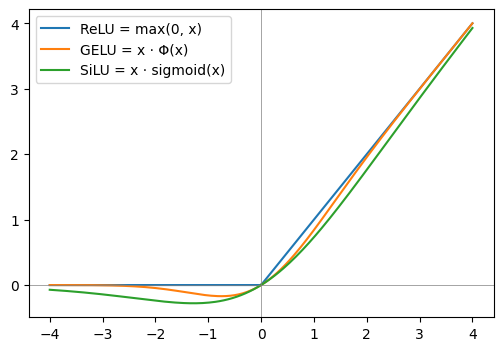

In [ ]:
import torch.nn.functional as F

x = torch.linspace(-4, 4, 200)
plt.figure(figsize=(6, 4))
plt.plot(x, F.relu(x), label="ReLU = max(0, x)")
plt.plot(x, F.gelu(x), label="GELU = x · Φ(x)")
plt.plot(x, F.silu(x), label="SiLU = x · sigmoid(x)")
plt.axhline(0, color="grey", lw=0.5)
plt.axvline(0, color="grey", lw=0.5)
plt.legend()
plt.show()

## A.2 LayerNorm and RMSNorm

Both rescale each token vector before attention and feed-forward. **LayerNorm** (Ba et al., 2016; GPT-2, lecture
figure) subtracts the mean and divides by the standard deviation. **RMSNorm** (Zhang & Sennrich, 2019; Qwen3) only
divides by the root mean square: no mean subtraction, one step less. Both then apply a learned scale (left out here).

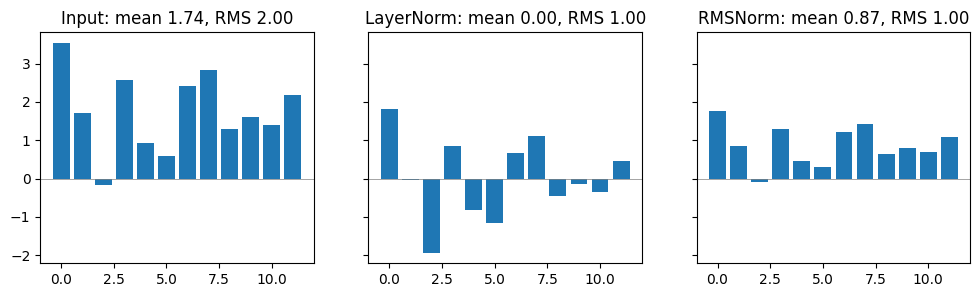

In [ ]:
torch.manual_seed(0)
v = torch.randn(12) + 2                            # one token vector, mean shifted away from 0
ln = (v - v.mean()) / v.std(unbiased=False)        # LayerNorm: subtract mean, divide by std
rms = v / v.pow(2).mean().sqrt()                   # RMSNorm: divide by root mean square only

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, (name, y) in zip(axes, [("Input", v), ("LayerNorm", ln), ("RMSNorm", rms)]):
    ax.bar(range(len(y)), y)
    ax.axhline(0, color="grey", lw=0.5)
    ax.set_title(f"{name}: mean {round(y.mean().item(), 2) + 0:.2f}, RMS {y.pow(2).mean().sqrt():.2f}")
plt.show()

## A.3 Rotary position embedding (RoPE)

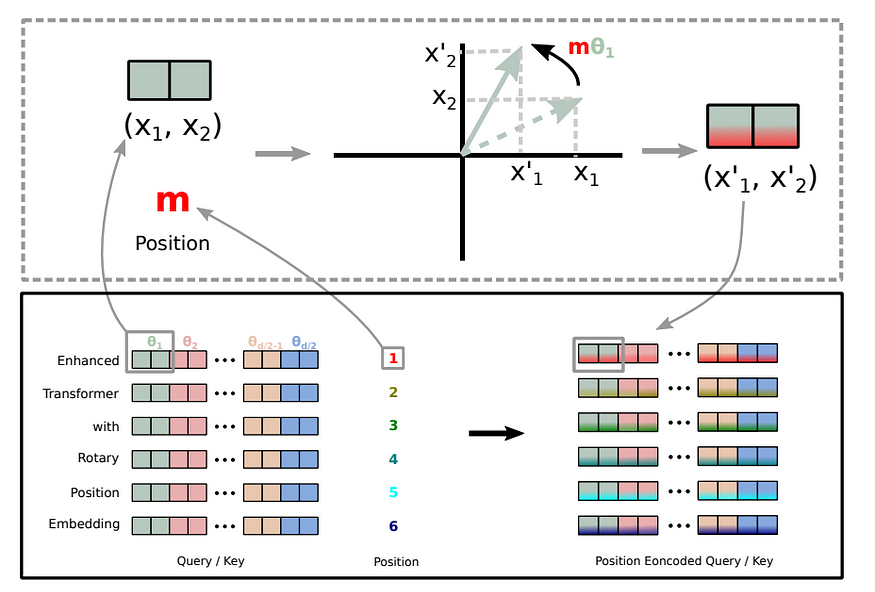

Source: Su et al., 2021, RoFormer: Enhanced Transformer with Rotary Position Embedding, arXiv:2104.09864, Figure 1

The lecture figure adds a position vector to the input embedding once. **RoPE** instead rotates every pair of
numbers in q and k by an angle m·θ, with m the position, inside every attention layer. The dot product q·k then
depends on how far apart two tokens are, not on where they stand. Qwen3: `rotary_emb`.

## A.4 Grouped-query attention (GQA)

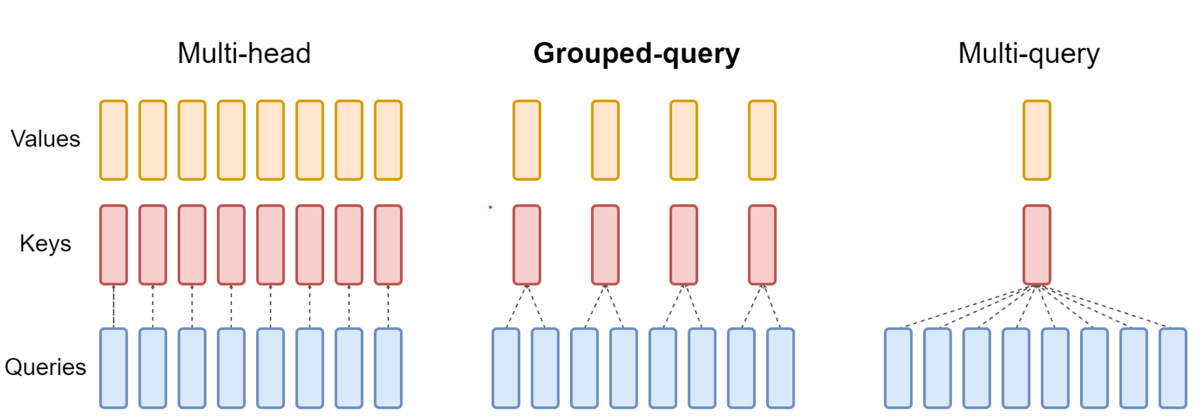

Source: Ainslie et al., 2023, GQA: Training Generalized Multi-Query Transformer Models from Multi-Head Checkpoints, arXiv:2305.13245

**Multi-head**: every query head has its own key and value head. **Grouped-query**: a group of query heads
shares one key/value head. Qwen3-0.6B has 16 query heads and 8 key/value heads, so two query heads share one,
as in the figure. Fewer keys and values to store and load during generation.

---
## References

- Hendrycks, D., & Gimpel, K. (2016). Gaussian Error Linear Units (GELUs). arXiv:1606.08415
- Elfwing, S., Uchibe, E., & Doya, K. (2017). Sigmoid-Weighted Linear Units for Neural Network Function Approximation in Reinforcement Learning. arXiv:1702.03118
- Ba, J. L., Kiros, J. R., & Hinton, G. E. (2016). Layer Normalization. arXiv:1607.06450
- Zhang, B., & Sennrich, R. (2019). Root Mean Square Layer Normalization. arXiv:1910.07467
- Xiao, G., Tian, Y., Chen, B., Han, S., & Lewis, M. (2023). Efficient Streaming Language Models with Attention Sinks. arXiv:2309.17453
- Raschka, S. (2025). The Big LLM Architecture Comparison. https://magazine.sebastianraschka.com/p/the-big-llm-architecture-comparison
- Su, J., Lu, Y., Pan, S., Murtadha, A., Wen, B., & Liu, Y. (2021). RoFormer: Enhanced Transformer with Rotary Position Embedding. arXiv:2104.09864
- Ainslie, J., Lee-Thorp, J., de Jong, M., Zemlyanskiy, Y., Lebrón, F., & Sanghai, S. (2023). GQA: Training Generalized Multi-Query Transformer Models from Multi-Head Checkpoints. arXiv:2305.13245
- Qwen Team (2025). Qwen3 Technical Report. arXiv:2505.09388
- Lecture figure: Chalvatzaki et al. (2023). Learning to Reason over Scene Graphs. arXiv:2305.07716, Figure 2